# Bài 5 (trang 26, mục IV.5) - Gom cụm MNIST bằng K-Means

**Sinh viên:** Nguyễn Đức Vinh  
**MSSV:** 6451071087

Áp dụng K-Means với 10 cụm lên dữ liệu MNIST, đối chiếu kết quả gom cụm với nhãn chữ số có sẵn và đánh giá bằng confusion matrix, Precision, Recall, F1-score.

> Chạy lần lượt các cell từ trên xuống dưới trong Google Colab. Mỗi notebook là một bài độc lập.

## 1. Thư viện và thông tin sinh viên

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             classification_report, precision_recall_fscore_support,
                             silhouette_score)
from scipy.optimize import linear_sum_assignment

print("Nguyễn Đức Vinh - MSSV: 6451071087")

Nguyễn Đức Vinh - MSSV: 6451071087


## 2. Đọc MNIST, chuẩn hóa và lấy mẫu phân tầng

In [2]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
(train_images, train_labels), (_, _) = tf.keras.datasets.mnist.load_data()
print("Kích thước train ban đầu:", train_images.shape)
X_all = train_images.astype("float32").reshape(-1, 28 * 28) / 255.0
y_all = train_labels

# K-Means trên toàn bộ 60.000 ảnh tốn nhiều tài nguyên; dùng mẫu phân tầng 10.000 ảnh
# để bảo đảm mỗi chữ số đều được đại diện. Có thể tăng SAMPLE_SIZE nếu máy đủ mạnh.
SAMPLE_SIZE = 10000
X, _, y, _ = train_test_split(
    X_all, y_all, train_size=SAMPLE_SIZE,
    random_state=42, stratify=y_all
)
print("Số ảnh dùng để gom cụm:", X.shape[0])
print("Tỷ lệ nhãn trong mẫu:")
print({int(k): int(v) for k, v in zip(*np.unique(y, return_counts=True))})

Nguyễn Đức Vinh - MSSV: 6451071087
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Kích thước train ban đầu: (60000, 28, 28)
Số ảnh dùng để gom cụm: 10000
Tỷ lệ nhãn trong mẫu:
{0: 987, 1: 1124, 2: 993, 3: 1022, 4: 974, 5: 904, 6: 986, 7: 1044, 8: 975, 9: 991}


## 3. Huấn luyện K-Means với 10 cụm

In [3]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
kmeans = KMeans(n_clusters=10, init="k-means++", n_init=10,
                max_iter=100, random_state=42)
cluster_labels = kmeans.fit_predict(X)
print("Inertia:", kmeans.inertia_)
print("Số cụm thực tế:", len(np.unique(cluster_labels)))
sil = silhouette_score(X, cluster_labels, sample_size=2000, random_state=42)
print("Silhouette (mẫu 2.000 ảnh):", round(float(sil), 4))

Nguyễn Đức Vinh - MSSV: 6451071087
Inertia: 392620.375
Số cụm thực tế: 10
Silhouette (mẫu 2.000 ảnh): 0.0532


## 4. Đối chiếu cụm với nhãn số có sẵn

Nguyễn Đức Vinh - MSSV: 6451071087
Accuracy sau khi ánh xạ nhãn cụm: 0.5453
              precision    recall  f1-score   support

           0     0.9485    0.7832    0.8579       987
           1     0.6660    0.5552    0.6055      1124
           2     0.8977    0.7422    0.8126       993
           3     0.5035    0.6350    0.5617      1022
           4     0.3887    0.3727    0.3805       974
           5     0.1538    0.1504    0.1521       904
           6     0.8492    0.8337    0.8414       986
           7     0.4381    0.4100    0.4236      1044
           8     0.4431    0.5272    0.4815       975
           9     0.3350    0.4107    0.3690       991

    accuracy                         0.5453     10000
   macro avg     0.5623    0.5420    0.5486     10000
weighted avg     0.5667    0.5453    0.5523     10000



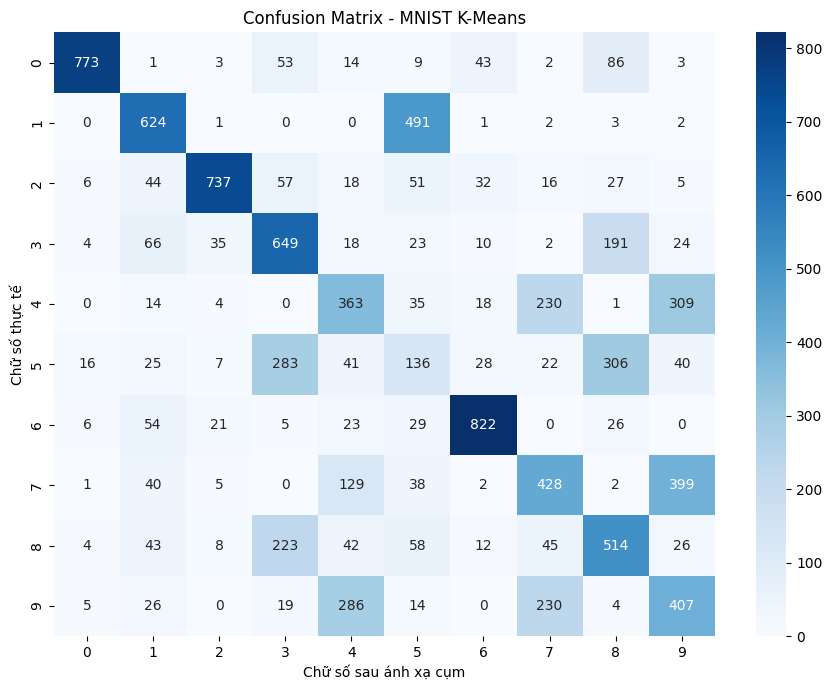

In [4]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
# Nhãn cụm K-Means chỉ là mã cụm; dùng Hungarian algorithm để ánh xạ tối ưu
# các mã cụm về chữ số thật trước khi lập confusion matrix.
contingency = confusion_matrix(y, cluster_labels, labels=np.arange(10))
row_ind, col_ind = linear_sum_assignment(-contingency)
cluster_to_digit = {int(cluster): int(digit) for digit, cluster in zip(row_ind, col_ind)}
mapped_predictions = np.array([cluster_to_digit[int(c)] for c in cluster_labels])

cm = confusion_matrix(y, mapped_predictions, labels=np.arange(10))
print("Accuracy sau khi ánh xạ nhãn cụm:", round(accuracy_score(y, mapped_predictions), 4))
print(classification_report(y, mapped_predictions, labels=np.arange(10),
                            digits=4, zero_division=0))
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=np.arange(10), yticklabels=np.arange(10))
plt.xlabel("Chữ số sau ánh xạ cụm")
plt.ylabel("Chữ số thực tế")
plt.title("Confusion Matrix - MNIST K-Means")
plt.tight_layout()
plt.show()

## 5. Hiển thị tâm cụm và một số ảnh

Nguyễn Đức Vinh - MSSV: 6451071087


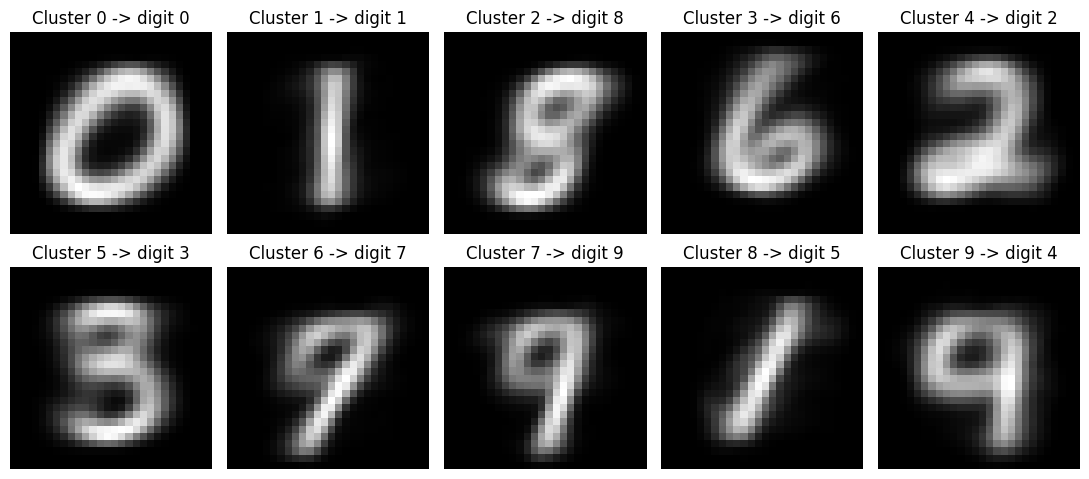

Ảnh 1: nhãn thật=6, cụm=3, nhãn ánh xạ=6


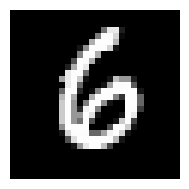

Ảnh 2: nhãn thật=5, cụm=5, nhãn ánh xạ=3


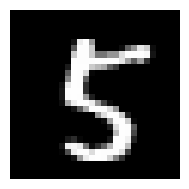

Ảnh 3: nhãn thật=8, cụm=6, nhãn ánh xạ=7


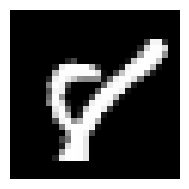

Ảnh 4: nhãn thật=5, cụm=5, nhãn ánh xạ=3


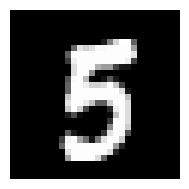

Ảnh 5: nhãn thật=8, cụm=5, nhãn ánh xạ=3


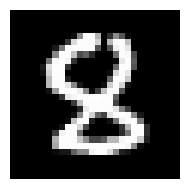

In [5]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for cluster_id, ax in enumerate(axes.ravel()):
    ax.imshow(kmeans.cluster_centers_[cluster_id].reshape(28, 28), cmap="gray")
    ax.set_title(f"Cluster {cluster_id} -> digit {cluster_to_digit[cluster_id]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

for i in range(5):
    plt.figure(figsize=(2.2, 2.2))
    plt.imshow(X[i].reshape(28, 28), cmap="gray")
    print(f"Ảnh {i+1}: nhãn thật={y[i]}, cụm={cluster_labels[i]}, "
          f"nhãn ánh xạ={mapped_predictions[i]}")
    plt.axis("off")
    plt.show()

## 6. Nhận xét

K-Means là thuật toán không giám sát nên mã cụm không mặc định trùng với chữ số. Vì vậy cần ánh xạ cụm sang chữ số trước khi tính confusion matrix và các chỉ số phân lớp. Thí nghiệm sử dụng mẫu phân tầng 10.000 ảnh từ tập train 60.000 ảnh để giảm chi phí tính toán; cần ghi rõ điều này trong báo cáo.